# Шаг 1. Готовые модели: откуда они берутся и как режут текст

В сессии 5 мы **сами** обучили мини-GPT: около 0,8 млн весов, 5 минут на процессоре.
Настоящие модели учат неделями на сотнях гигабайт текста — это дорого. Зато результат можно **скачать** и пользоваться.

Главное место, где лежат готовые модели, — **Hugging Face Hub** (huggingface.co). Там сотни тысяч моделей:
для текста, картинок, звука. Модель на Hub — это папка из нескольких файлов:

| Файл | Что внутри |
|------|------------|
| `config.json` | устройство сети: сколько слоёв, какой длины векторы, сколько голов внимания |
| `model.safetensors` | сами веса — миллионы чисел, ради которых и обучали |
| `tokenizer.json`, `vocab.txt` | словарь: как резать текст на токены и какой у каждого номер |

В этой сессии три главные модели:

| Короткое имя | Модель | Что умеет |
|--------------|--------|-----------|
| `bert` | rubert-tiny2 | понимает смысл фразы (шаги 2–5) |
| `gpt` | ruGPT-3 small | продолжает русский текст (шаг 6) |
| `chat` | Qwen2.5-0.5B-Instruct | отвечает на вопросы, как чат-бот (шаг 7) |

Функции `load_tokenizer` и `load_model` из `common.py` при первом запуске скачивают модель в папку `data/hf`,
а дальше берут её оттуда без интернета.

In [1]:
# Настройка для Google Colab. На своём компьютере эта ячейка ничего не делает.
# В Colab нужна папка machine_vision на Google Диске (в ней session05 и session06).
import os
import sys

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive:
    drive.mount("/content/drive")
    COLAB_ROOT = "/content/drive/MyDrive/machine_vision"
    os.chdir(f"{COLAB_ROOT}/session06")  # здесь лежит common.py; модели скачаются в machine_vision/data/hf
    sys.path.insert(0, os.getcwd())
    !pip install -q transformers

## Общий модуль `common.py`

| Имя | Что делает |
|-----|------------|
| `MODELS` | короткие имена моделей сессии и их адреса на Hugging Face Hub |
| `load_tokenizer(name)`, `load_model(name, kind)` | словарь и сама модель (скачиваются один раз в `data/hf`) |
| `count_params(model)` | сколько весов в сети |
| `Embedder()` | фраза → вектор смысла (шаги 3–4) |
| `load_genres()`, `load_onegin()`, `onegin_stanzas()` | тексты по жанрам из `genres.csv` и «Онегин» из сессии 5 |
| `show()` | показать графики |

## 1. Сколько весов в настоящих моделях

Загрузим все три модели и посчитаем веса — так же, как считали у своих сетей в сессиях 3–5.
Первая загрузка может занять пару минут (скачивание), следующие — секунды.

In [2]:
import matplotlib.pyplot as plt

from common import MODELS, count_params, load_model, load_tokenizer, show

MINI_GPT = 820_000         # весов в мини-GPT из сессии 5 (шаг 6)

sizes = {"мини-GPT\n(сессия 5)": MINI_GPT}
for name, kind in [("bert", "base"), ("gpt", "lm"), ("chat", "lm")]:
    model = load_model(name, kind)
    n = count_params(model)
    sizes[f"{name}\n{MODELS[name].split('/')[1]}"] = n
    print(f"{MODELS[name]:45s} {n / 1e6:7.1f} млн весов, в {n / MINI_GPT:4.0f} раз больше мини-GPT")
    del model

cointegrated/rubert-tiny2                        29.2 млн весов, в   36 раз больше мини-GPT


ai-forever/rugpt3small_based_on_gpt2            125.2 млн весов, в  153 раз больше мини-GPT


Qwen/Qwen2.5-0.5B-Instruct                      494.0 млн весов, в  602 раз больше мини-GPT


Столбики приходится рисовать в **логарифмическом** масштабе: каждая следующая отметка оси — в 10 раз больше предыдущей.
В обычном масштабе мини-GPT было бы просто не видно. А самые большие чат-боты ещё в сотни раз больше Qwen.

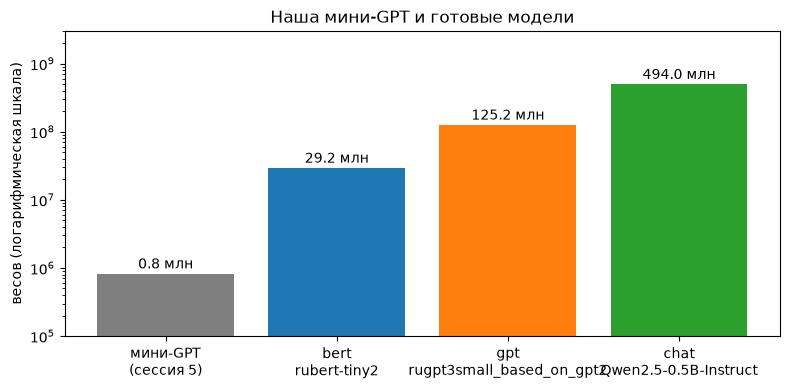

In [3]:
plt.figure(figsize=(8, 4))
names = list(sizes)
plt.bar(names, [sizes[n] for n in names], color=["tab:gray", "tab:blue", "tab:orange", "tab:green"])
for i, n in enumerate(names):
    plt.text(i, sizes[n] * 1.2, f"{sizes[n] / 1e6:.1f} млн", ha="center")
plt.yscale("log")
plt.ylim(1e5, 3e9)
plt.ylabel("весов (логарифмическая шкала)")
plt.title("Наша мини-GPT и готовые модели")
plt.tight_layout()
plt.savefig("model_sizes.png", dpi=100)
show()

## 2. Одна строка — три токенизатора

В сессии 5 (шаг 1) мы резали текст на **символы** и придумали BPE — склейку частых пар.
Все три готовые модели используют вариации BPE, но словари у них разные: каждый собран по своим текстам.

- **rubert-tiny2** учили на русском и английском — русские слова часто целиком. `##` в начале кусочка значит «продолжение слова».
- **ruGPT-3** учили на русском — тоже крупные куски. Пробел приклеен к началу слова.
- **Qwen** учили в основном на английском и китайском — русские слова режутся мельче.

Чтобы было видно границы, каждый токен показан в квадратных скобках, а пробел — символом `·`.

In [4]:
tokenizers = {name: load_tokenizer(name) for name in ["bert", "gpt", "chat"]}


def pieces(name, text):
    """Текст → список кусочков-токенов (служебные токены [CLS]/[SEP] не показываем)."""
    tok = tokenizers[name]
    ids = tok(text, add_special_tokens=False)["input_ids"]
    if name == "bert":
        return tok.convert_ids_to_tokens(ids)            # у BERT кусочки и так читаемые
    return [tok.decode([i]) for i in ids]                # у GPT и Qwen собираем кусочек из байтов


def show_pieces(text):
    print(f"«{text}» — {len(text)} символов")
    for name in tokenizers:
        p = pieces(name, text)
        print(f"  {name:5s} {len(p):3d} токенов: " + " ".join(f"[{x.replace(' ', '·')}]" for x in p))


show_pieces("Мой дядя самых честных правил")
show_pieces("My uncle has most honest principles")

«Мой дядя самых честных правил» — 29 символов
  bert    5 токенов: [Мой] [дядя] [самых] [честных] [правил]
  gpt     6 токенов: [Мой] [·дядя] [·самых] [·чест] [ных] [·правил]
  chat   11 токенов: [М] [ой] [·д] [яд] [я] [·самых] [·ч] [ест] [ных] [·прав] [ил]
«My uncle has most honest principles» — 35 символов
  bert    7 токенов: [My] [uncle] [has] [most] [hon] [##est] [principles]
  gpt     9 токенов: [My] [·un] [cle] [·has] [·most] [·hon] [est] [·princip] [les]
  chat    6 токенов: [My] [·uncle] [·has] [·most] [·honest] [·principles]


**Что видно:**
- русская строка у русских моделей — 5–6 токенов (почти по слову на токен), у Qwen — 11: «дядя» превратилась в «д + яд + я»;
- английская строка — наоборот: Qwen режет её экономнее всех, а BERT и ruGPT — мельче;
- значит, для Qwen русский текст «дороже»: тот же смысл занимает больше токенов, и модель видит за раз меньше текста.
  Платные чат-боты считают деньги именно в токенах — русский там обычно дороже английского.

## 3. Кто экономнее: считаем токены на разных текстах

In [5]:
samples = {
    "Онегин": "Мой дядя самых честных правил, когда не в шутку занемог, он уважать себя заставил и лучше выдумать не мог.",
    "новость": "Центральный банк сохранил ключевую ставку на прежнем уровне. Решение объявлено в пятницу.",
    "английский": "The Central Bank kept the key interest rate unchanged. The decision was announced on Friday.",
    "код": "for i in range(10):\n    print(i * i)",
    "смайлики": "Отлично 😀👍🔥",
}
print(f"{'текст':12s} {'символов':>9s} " + " ".join(f"{n:>6s}" for n in tokenizers))
for label, text in samples.items():
    counts = [len(tokenizers[n](text, add_special_tokens=False)["input_ids"]) for n in tokenizers]
    print(f"{label:12s} {len(text):9d} " + " ".join(f"{c:6d}" for c in counts))

текст         символов   bert    gpt   chat
Онегин             106     25     26     37
новость             89     14     16     29
английский          92     19     22     17
код                 36     14     15     14
смайлики            11      2     11      6


Смайлики BERT вообще не знает — они превращаются в служебный токен `[UNK]` («неизвестно»): модель не отличит 😀 от 😡.

GPT и Qwen режут текст на **байты** (в компьютере любой символ — это от 1 до 4 байт), поэтому могут записать **любой** символ.
Частые смайлики Qwen видел так много раз, что держит целиком, одним токеном. А редкий символ, например египетский иероглиф,
разбивается на кусочки-байты: по отдельности они не являются буквами и печатаются как `�`.

In [6]:
print("BERT видит смайлики как:", pieces("bert", "Отлично 😀 😡"))
print("Qwen видит смайлик как:  ", pieces("chat", "😀"), "— один токен")
print("Qwen видит иероглиф 𓀀 как:", pieces("chat", "𓀀"), "— три кусочка байтов")

BERT видит смайлики как: ['Отлично', '[UNK]', '[UNK]']
Qwen видит смайлик как:   ['😀'] — один токен
Qwen видит иероглиф 𓀀 как: ['�', '�', '�'] — три кусочка байтов


## 4. Размер словаря и служебные токены

Помните служебную точку «.» у биграмм из сессии 5 — «начало / конец имени»? У настоящих моделей такие служебные токены тоже есть:

- у BERT каждый текст начинается с `[CLS]` и заканчивается `[SEP]`; вектор на месте `[CLS]` потом используют как «смысл всей фразы» (шаги 2–4);
- у Qwen диалог размечают токенами `<|im_start|>` и `<|im_end|>` — «здесь начинается реплика», «здесь закончилась» (шаг 7).

In [7]:
for name, tok in tokenizers.items():
    print(f"{name:5s} словарь: {len(tok):7d} токенов")
print("в сессии 5:   75 символов")

ids = tokenizers["bert"]("Привет, мир!")["input_ids"]
print("\nBERT добавляет служебные токены:", tokenizers["bert"].convert_ids_to_tokens(ids))
print("их номера:", ids)
print("служебные токены Qwen:", tokenizers["chat"].all_special_tokens[:6])

bert  словарь:   83828 токенов
gpt   словарь:   50257 токенов
chat  словарь:  151665 токенов
в сессии 5:   75 символов

BERT добавляет служебные токены: ['[CLS]', 'Привет', ',', 'мир', '!', '[SEP]']
их номера: [2, 51343, 16, 9311, 5, 3]
служебные токены Qwen: ['<|im_end|>', '<|endoftext|>', '<|im_start|>', '<|object_ref_start|>', '<|object_ref_end|>', '<|box_start|>']


## 5. Незнакомые слова

Словарь не может содержать **все** слова. Редкое слово модель собирает из кусочков, как из конструктора, —
ровно так, как BPE из сессии 5 записывал «нейросеть» по слогам.

In [8]:
for word in ["кот", "котёнок", "нейросеть", "Онегин", "автомобилестроение", "пупырышкин"]:
    print(f"{word:20s} BERT: {pieces('bert', word)}   GPT: {pieces('gpt', ' ' + word)}")

кот                  BERT: ['кот']   GPT: [' кот']
котёнок              BERT: ['кот', '##ёнок']   GPT: [' кот', 'ёнок']
нейросеть            BERT: ['нейрос', '##еть']   GPT: [' ней', 'рос', 'еть']
Онегин               BERT: ['Он', '##еги', '##н']   GPT: [' О', 'не', 'гин']
автомобилестроение   BERT: ['автомобиле', '##строение']   GPT: [' автомобиле', 'строение']
пупырышкин           BERT: ['пуп', '##ыры', '##шкин']   GPT: [' пуп', 'ы', 'ры', 'шкин']


## Попробуйте сами

1. Запишите своё имя и фамилию во всех трёх токенизаторах. У кого меньше всего токенов?
2. Найдите русское слово, которое BERT держит **целиком**, а Qwen режет на 4 и больше кусочков.
3. Напишите слово с опечаткой («превет», «сабака»). Как изменилось число токенов? Почему?
4. Сравните число токенов у одной и той же фразы на русском, английском и любом третьем языке.
5. Во сколько раз Qwen больше мини-GPT? Если мини-GPT училась 5 минут, сколько бы училась такая модель
   на том же компьютере, если время растёт пропорционально числу весов и количеству текста (Qwen видел примерно в 10⁷ раз больше текста)?